# 05 · Uplift

Notebooks 03–04 looked at promotions everyone sees (shelf discounts, displays, mailers).
This one looks at **targeted campaigns**, where the store chooses which households get coupons.

The question isn't "who is likely to spend?" but **"whose spending goes up *because* they got the campaign?"**
Sending coupons to people who would have shopped anyway just gives away margin.

**Plan**

1. Build one row per household per TypeA campaign: shopping behaviour in the 8 weeks before, and spend during the campaign.
2. Check how different targeted and non-targeted households were *before* the campaign (the store didn't pick at random).
3. Estimate the average campaign effect three ways, from naive to more careful.
4. Train an uplift model to rank households by how much the campaign changes their spend.
5. Work out which households are worth targeting once coupon and contact costs are counted.

In [30]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## Settings

In [31]:
CAMPAIGN_TYPES = ["TypeA"]   # the big campaigns (~1,100 households each in notebook 01)
PRE_DAYS = 56                # 8 weeks of behaviour before each campaign

MARGIN = 0.30                # gross margin on extra spend (same assumption as notebook 04)
CONTACT_COST = 0.50          # cost to send one household the campaign (assumption)

PS_MIN, PS_MAX = 0.05, 0.95  # drop households the propensity model is almost certain about
N_FOLDS = 5                  # cross-fitting: every household gets an out-of-fold score
CLIP_PCT = 0.025             # trim extreme spend changes (top/bottom 2.5% per campaign)
N_BOOT = 300                 # bootstrap samples for confidence intervals
SEED = 42

## Load data

In [32]:
tx = pd.read_parquet(PROCESSED / "transactions_clean.parquet",
                     columns=["household_key", "day", "basket_id", "sales_value", "retail_disc_amt",
                              "coupon_disc_amt", "department", "brand"])
tx["department"] = tx["department"].astype(str)
tx["brand"] = tx["brand"].astype(str)

campaigns = pd.read_parquet(PROCESSED / "campaigns.parquet")
camp_hh = pd.read_parquet(PROCESSED / "campaign_households.parquet")
redeem = pd.read_parquet(PROCESSED / "coupon_redemptions.parquet")

target_campaigns = campaigns.loc[campaigns["campaign_type"].isin(CAMPAIGN_TYPES)].sort_values("start_day")
print(f"transactions cover days {tx['day'].min()}–{tx['day'].max()}")
target_campaigns[["campaign", "campaign_type", "start_day", "end_day", "duration_days", "households_targeted"]]

transactions cover days 111–705


,campaign,campaign_type,start_day,end_day,duration_days,households_targeted
0,26,TypeA,224,264,41,332
4,30,TypeA,323,369,47,361
12,8,TypeA,412,460,49,1076
17,13,TypeA,504,551,48,1077
22,18,TypeA,587,642,56,1133


## Build the household table

For each campaign:

- **Treated:** households that received this campaign.
- **Control:** households that didn't receive this campaign *or any other campaign running in the same period*,
  so the comparison isn't muddied by other coupons.
- Only households that shopped at least once in the 8 weeks before are included (we need their history).

**Outcome:** change in weekly spend, campaign period vs. the 8 weeks before.
Using the change rather than the level removes a lot of the difference between heavy and light shoppers.

In [33]:
def window_features(start, end):
    w = tx.loc[tx["day"].between(start, end)]
    g = w.groupby("household_key")
    f = pd.DataFrame({
        "spend": g["sales_value"].sum(),
        "trips": g["basket_id"].nunique(),
        "last_day": g["day"].max(),
        "retail_disc": g["retail_disc_amt"].sum(),
        "coupon_disc": g["coupon_disc_amt"].sum(),
        "departments": g["department"].nunique(),
    })
    f["private_spend"] = w.loc[w["brand"] == "Private"].groupby("household_key")["sales_value"].sum()
    return f.fillna({"private_spend": 0})

camp_start = camp_hh.merge(campaigns[["campaign", "start_day"]], on="campaign")
rows = []

for _, c in target_campaigns.iterrows():
    s, e = int(c["start_day"]), int(c["end_day"])
    pre = window_features(s - PRE_DAYS, s - 1)
    post = window_features(s, e)
    pre_weeks, post_weeks = PRE_DAYS / 7, (e - s + 1) / 7

    overlapping = campaigns.loc[(campaigns["start_day"] <= e) & (campaigns["end_day"] >= s - PRE_DAYS), "campaign"]
    treated = set(camp_hh.loc[camp_hh["campaign"] == c["campaign"], "household_key"])
    busy = set(camp_hh.loc[camp_hh["campaign"].isin(overlapping), "household_key"])

    d = pd.DataFrame(index=pre.index)
    d["treated"] = d.index.isin(treated).astype(int)
    d = d.loc[(d["treated"] == 1) | (~d.index.isin(busy))].copy()
    p = pre.loc[d.index]

    d["pre_weekly_spend"] = p["spend"] / pre_weeks
    d["pre_trips_per_week"] = p["trips"] / pre_weeks
    d["pre_avg_basket"] = p["spend"] / p["trips"]
    d["recency_days"] = s - p["last_day"]
    d["pre_disc_share"] = p["retail_disc"] / (p["spend"] + p["retail_disc"] + p["coupon_disc"])
    d["pre_coupon_share"] = p["coupon_disc"] / (p["spend"] + p["retail_disc"] + p["coupon_disc"])
    d["pre_departments"] = p["departments"]
    d["pre_private_share"] = p["private_spend"] / p["spend"]
    d["prior_redemptions"] = redeem.loc[redeem["day"] < s].groupby("household_key").size().reindex(d.index).fillna(0)
    d["prior_campaigns"] = camp_start.loc[camp_start["start_day"] < s].groupby("household_key").size().reindex(d.index).fillna(0)

    d["post_weekly_spend"] = post["spend"].reindex(d.index).fillna(0) / post_weeks
    d["post_coupon_disc"] = post["coupon_disc"].reindex(d.index).fillna(0)
    d["y"] = d["post_weekly_spend"] - d["pre_weekly_spend"]
    d["campaign"] = c["campaign"]
    d["campaign_weeks"] = post_weeks
    rows.append(d.reset_index())

data = pd.concat(rows, ignore_index=True)
FEATURES = ["pre_weekly_spend", "pre_trips_per_week", "pre_avg_basket", "recency_days", "pre_disc_share",
            "pre_coupon_share", "pre_departments", "pre_private_share", "prior_redemptions", "prior_campaigns"]

data.groupby("campaign")["treated"].agg(rows="size", treated="sum").assign(control=lambda d: d["rows"] - d["treated"])

,rows,treated,control
campaign,,,
8,2004,1063,941
13,1978,1063,915
18,1960,1114,846
26,2150,324,1826
30,2063,352,1711


## Were targeted households different to begin with?

Standardised difference = gap in means divided by the pooled standard deviation.
Anything above about 0.1 is a meaningful imbalance.

In [34]:
g = data.groupby("treated")[FEATURES]
balance = pd.DataFrame({"control": g.mean().loc[0], "treated": g.mean().loc[1]})
pooled_sd = np.sqrt((g.var().loc[0] + g.var().loc[1]) / 2)
balance["std_diff"] = (balance["treated"] - balance["control"]) / pooled_sd
balance.sort_values("std_diff", key=abs, ascending=False)

,control,treated,std_diff
prior_campaigns,0.07,2.00,1.37
pre_departments,5.39,7.32,0.79
pre_weekly_spend,26.03,51.28,0.69
pre_trips_per_week,0.93,1.72,0.58
recency_days,12.48,6.24,-0.58
prior_redemptions,0.01,0.52,0.40
pre_avg_basket,30.83,36.10,0.20
pre_coupon_share,0.00,0.00,0.11
pre_disc_share,0.15,0.16,0.03
pre_private_share,0.23,0.23,-0.03


## Propensity: how predictable was targeting?

A model predicts the chance each household gets targeted from its pre-campaign behaviour.
If it predicts well, the store was clearly choosing a certain kind of customer. I use it to

- drop households with almost no comparable counterpart (propensity below 5% or above 95%), and
- weight the rest so treated and control look alike (inverse propensity weighting).

propensity AUC: 0.88  (0.5 = random targeting, 1.0 = fully predictable)


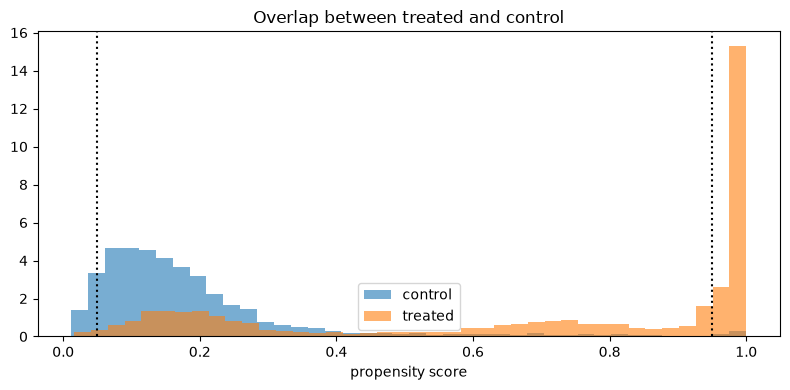

In [35]:
ps_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
data["ps"] = cross_val_predict(ps_model, data[FEATURES], data["treated"], cv=5, method="predict_proba")[:, 1]
print(f"propensity AUC: {roc_auc_score(data['treated'], data['ps']):.2f}  (0.5 = random targeting, 1.0 = fully predictable)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data.loc[data["treated"] == 0, "ps"], bins=40, alpha=0.6, label="control", density=True)
ax.hist(data.loc[data["treated"] == 1, "ps"], bins=40, alpha=0.6, label="treated", density=True)
ax.axvline(PS_MIN, color="black", ls=":"); ax.axvline(PS_MAX, color="black", ls=":")
ax.set_xlabel("propensity score"); ax.set_title("Overlap between treated and control")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "05_propensity_overlap.png", dpi=150)
plt.show()

In [36]:
trim = data.loc[data["ps"].between(PS_MIN, PS_MAX)].copy()
trim["w"] = np.where(trim["treated"] == 1, 1 / trim["ps"], 1 / (1 - trim["ps"]))
print(f"kept {len(trim):,} of {len(data):,} rows after trimming")

g = trim.groupby("treated")
wmean = lambda d, col: np.average(d[col], weights=d["w"])
balance_after = pd.DataFrame({
    "std_diff_before": balance["std_diff"],
    "std_diff_after_weighting": [
        (wmean(trim[trim.treated == 1], f) - wmean(trim[trim.treated == 0], f)) / pooled_sd[f] for f in FEATURES
    ],
})
balance_after

kept 7,852 of 10,155 rows after trimming


,std_diff_before,std_diff_after_weighting
pre_weekly_spend,0.69,0.10
pre_trips_per_week,0.58,0.09
pre_avg_basket,0.20,0.06
recency_days,-0.58,-0.11
pre_disc_share,0.03,0.01
pre_coupon_share,0.11,-0.01
pre_departments,0.79,0.14
pre_private_share,-0.03,0.01
prior_redemptions,0.40,-0.00
prior_campaigns,1.37,0.05


## Average campaign effect, three ways

| Method | What it compares |
|---|---|
| Naive | campaign-period spend, treated vs. control |
| Difference-in-differences | *change* in spend, treated vs. control |
| Weighted DiD | same, after weighting control to look like the treated group |

If the naive number is much bigger than the others, most of the apparent "effect" was the store
picking customers who already spent more.

In [37]:
def diff(d, col, weights=None):
    t, c = d[d["treated"] == 1], d[d["treated"] == 0]
    if weights is None:
        return t[col].mean() - c[col].mean()
    return np.average(t[col], weights=t[weights]) - np.average(c[col], weights=c[weights])

effects = pd.Series({
    "naive (campaign-period spend)": diff(data, "post_weekly_spend"),
    "difference-in-differences": diff(data, "y"),
    "weighted DiD (trimmed)": diff(trim, "y", "w"),
}, name="extra spend per household per week")
effects.to_frame()

,extra spend per household per week
naive (campaign-period spend),25.62
difference-in-differences,0.37
weighted DiD (trimmed),2.17


In [38]:
# effect per campaign, weighted DiD
per_campaign = trim.groupby("campaign").apply(
    lambda d: pd.Series({"households": len(d), "treated": d["treated"].sum(),
                         "weighted_did": diff(d, "y", "w"),
                         "weeks": d["campaign_weeks"].iloc[0]}),
    include_groups=False,
)
per_campaign

,households,treated,weighted_did,weeks
campaign,,,,
8,"1,708.00",819.00,2.23,7.00
13,"1,307.00",456.00,2.82,6.86
18,988.00,251.00,0.34,8.00
26,"1,941.00",310.00,2.68,5.86
30,"1,908.00",315.00,1.05,6.71


## Uplift model

**T-learner:** two LightGBM models, one trained on treated households and one on control, both predicting the
change in weekly spend. A household's predicted uplift is the difference between the two predictions.
Training uses the propensity weights so the two groups are comparable.

Three things keep it honest, because individual spend changes are very noisy compared with a ~$2/week effect:

- **Clipped outcome:** the most extreme 2.5% of spend changes at each end (per campaign) are capped, so a few
  households moving house or throwing a party don't drive the model.
- **Heavily regularised trees:** small trees and large leaves, so the model can only learn broad patterns.
- **Cross-fitting:** households are split into 5 folds; each fold is scored by models trained on the other four.
  Every household gets an out-of-sample score, and the evaluation uses all of them instead of one small test set.

In [39]:
lo_y = trim.groupby("campaign")["y"].transform(lambda v: v.quantile(CLIP_PCT))
hi_y = trim.groupby("campaign")["y"].transform(lambda v: v.quantile(1 - CLIP_PCT))
trim["y_clip"] = trim["y"].clip(lo_y, hi_y)

params = dict(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
              random_state=SEED, verbose=-1)

def fit_t_learner(d):
    t, c = d[d["treated"] == 1], d[d["treated"] == 0]
    m1 = lgb.LGBMRegressor(**params).fit(t[FEATURES], t["y_clip"], sample_weight=t["w"])
    m0 = lgb.LGBMRegressor(**params).fit(c[FEATURES], c["y_clip"], sample_weight=c["w"])
    return m1, m0

trim["uplift_pred"] = np.nan
trim["fold"] = -1
for k, (tr, te) in enumerate(GroupKFold(n_splits=N_FOLDS).split(trim, groups=trim["household_key"])):
    m1, m0 = fit_t_learner(trim.iloc[tr])
    idx = trim.index[te]
    trim.loc[idx, "uplift_pred"] = m1.predict(trim.loc[idx, FEATURES]) - m0.predict(trim.loc[idx, FEATURES])
    trim.loc[idx, "fold"] = k

scored = trim
scored["uplift_pred"].describe()

count   7,852.00
mean        3.37
std         4.59
min       -20.30
25%         0.89
50%         3.44
75%         6.06
max        25.51
Name: uplift_pred, dtype: float64

## Does the ranking hold up out of sample?

Split households into five groups by their out-of-fold predicted uplift. In each group, compare the actual
change in spend for treated vs. control, with a bootstrap 90% interval.
If the model works, actual uplift should rise from group 1 to group 5 and the top group should clearly beat the bottom one.

rank correlation between group and actual uplift: 0.60  (1.0 = perfect ordering)
top group minus bottom group: 0.06 per week


,households,treated,predicted_uplift,actual_uplift,ci_low,ci_high,pre_weekly_spend
uplift_group,,,,,,,
1 lowest,1571,557,-3.01,2.30,0.00,4.70,48.92
2,1570,406,1.43,0.72,-1.39,2.57,27.53
3,1570,383,3.45,2.49,0.59,4.71,23.74
4,1570,348,5.50,3.41,1.35,5.48,24.18
5 highest,1571,457,9.49,2.36,-0.26,4.65,36.17


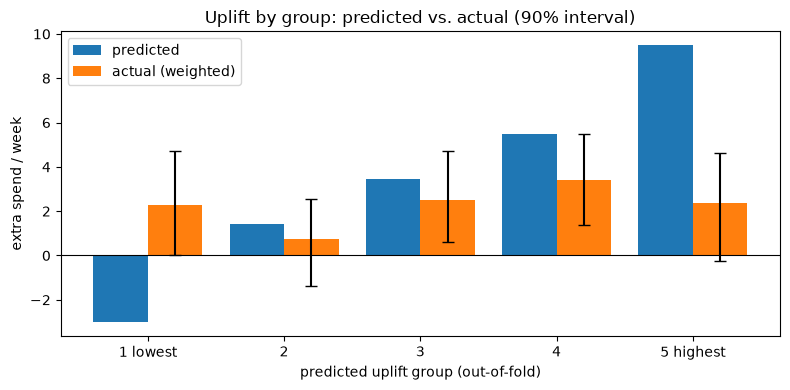

In [40]:
def group_effect(d, col="y_clip"):
    return diff(d, col, "w") if d["treated"].nunique() == 2 else np.nan

def bootstrap_ci(d, col="y_clip", n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    hh = d["household_key"].unique()
    by_hh = {h: g for h, g in d.groupby("household_key")}
    stats = []
    for _ in range(n):
        sample = pd.concat([by_hh[h] for h in rng.choice(hh, len(hh), replace=True)])
        stats.append(group_effect(sample, col))
    return np.nanpercentile(stats, [5, 95])

scored["uplift_group"] = pd.qcut(scored["uplift_pred"].rank(method="first"), 5,
                                 labels=["1 lowest", "2", "3", "4", "5 highest"])

rows_g = []
for name, d in scored.groupby("uplift_group", observed=True):
    lo_ci, hi_ci = bootstrap_ci(d)
    rows_g.append({"uplift_group": name, "households": len(d), "treated": d["treated"].sum(),
                   "predicted_uplift": d["uplift_pred"].mean(), "actual_uplift": group_effect(d),
                   "ci_low": lo_ci, "ci_high": hi_ci, "pre_weekly_spend": d["pre_weekly_spend"].mean()})
by_group = pd.DataFrame(rows_g).set_index("uplift_group")

rank_corr = by_group["actual_uplift"].reset_index(drop=True).corr(pd.Series(range(5)), method="spearman")
top_vs_bottom = by_group["actual_uplift"].iloc[-1] - by_group["actual_uplift"].iloc[0]
print(f"rank correlation between group and actual uplift: {rank_corr:.2f}  (1.0 = perfect ordering)")
print(f"top group minus bottom group: {top_vs_bottom:,.2f} per week")
display(by_group)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(by_group))
ax.bar(x - 0.2, by_group["predicted_uplift"], width=0.4, label="predicted")
ax.bar(x + 0.2, by_group["actual_uplift"], width=0.4, label="actual (weighted)",
       yerr=[by_group["actual_uplift"] - by_group["ci_low"], by_group["ci_high"] - by_group["actual_uplift"]], capsize=4)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, by_group.index)
ax.set_xlabel("predicted uplift group (out-of-fold)")
ax.set_ylabel("extra spend / week")
ax.set_title("Uplift by group: predicted vs. actual (90% interval)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "05_uplift_by_group.png", dpi=150)
plt.show()

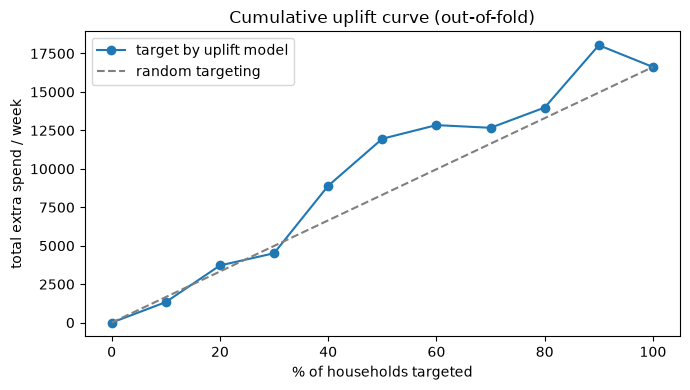

In [41]:
# cumulative uplift curve: targeting the top x% by predicted uplift vs. picking at random
ranked = scored.sort_values("uplift_pred", ascending=False).reset_index(drop=True)
fractions = np.linspace(0.1, 1.0, 10)
curve = [group_effect(ranked.iloc[: int(len(ranked) * f)]) * int(len(ranked) * f) for f in fractions]
overall = curve[-1]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([0, *fractions * 100], [0, *curve], marker="o", label="target by uplift model")
ax.plot([0, 100], [0, overall], ls="--", color="grey", label="random targeting")
ax.set_xlabel("% of households targeted")
ax.set_ylabel("total extra spend / week")
ax.set_title("Cumulative uplift curve (out-of-fold)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "05_uplift_curve.png", dpi=150)
plt.show()

## Is the campaign worth it?

A targeted household costs the coupon discounts it redeems (above what control households got) plus a contact cost.
It pays back through extra spend × margin over the campaign period.

**Important:** picking "the groups that pay back" after looking at their actual results would be cherry-picking.
So the targeting comparison only uses a rule decided in advance: target the top 40% by predicted uplift.
It only counts as a real improvement if its interval sits clearly above the "target everyone" result.

In [42]:
coupon_cost = diff(trim, "post_coupon_disc", "w")
avg_weeks = trim["campaign_weeks"].mean()
cost_per_household = max(coupon_cost, 0) + CONTACT_COST
print(f"extra coupon cost per targeted household: {coupon_cost:,.2f}")
print(f"cost per targeted household (incl. contact): {cost_per_household:,.2f}")
print(f"average campaign length: {avg_weeks:.1f} weeks")
print()

def net_per_household(d):
    return group_effect(d) * avg_weeks * MARGIN - cost_per_household

top40 = scored.loc[scored["uplift_pred"] >= scored["uplift_pred"].quantile(0.60)]
strategies = {"target everyone (what the store did)": scored, "target top 40% by model": top40}

rows_s = []
for name, d in strategies.items():
    est = net_per_household(d)
    rng = np.random.default_rng(SEED)
    hh = d["household_key"].unique()
    by_hh = {h: g for h, g in d.groupby("household_key")}
    boots = [net_per_household(pd.concat([by_hh[h] for h in rng.choice(hh, len(hh))])) for _ in range(N_BOOT)]
    lo_ci, hi_ci = np.nanpercentile(boots, [5, 95])
    rows_s.append({"strategy": name, "households": len(d), "extra_spend_per_week": group_effect(d),
                   "net_profit_per_targeted_hh": est, "ci_low": lo_ci, "ci_high": hi_ci})
econ = pd.DataFrame(rows_s).set_index("strategy")
econ

extra coupon cost per targeted household: 0.53
cost per targeted household (incl. contact): 1.03
average campaign length: 6.8 weeks



,households,extra_spend_per_week,net_profit_per_targeted_hh,ci_low,ci_high
strategy,,,,,
target everyone (what the store did),7852,2.12,3.26,1.38,5.17
target top 40% by model,3141,2.83,4.70,1.48,8.24


## Who are they?

The classic four uplift segments, simplified for a spend outcome:

| Segment | Rule here | What to do |
|---|---|---|
| **Persuadables** | top 40% of predicted uplift | target |
| **Sure things** | low uplift, above-median spend | don't need a coupon |
| **Lost causes** | low uplift, below-median spend | don't bother |
| **Sleeping dogs** | predicted uplift below zero (bottom 20%) | avoid, the campaign may put them off |

Check the `actual_uplift` column before trusting these labels: if it doesn't follow the predicted order,
the segments are describing noise, not real differences in response.

In [43]:
hi = scored["uplift_pred"].quantile(0.60)
lo = scored["uplift_pred"].quantile(0.20)
median_spend = scored["pre_weekly_spend"].median()

def segment(r):
    if r["uplift_pred"] >= hi: return "Persuadables"
    if r["uplift_pred"] < min(lo, 0): return "Sleeping dogs"
    return "Sure things" if r["pre_weekly_spend"] >= median_spend else "Lost causes"

scored["segment"] = scored.apply(segment, axis=1)

profile = scored.groupby("segment").agg(
    households=("household_key", "size"),
    predicted_uplift=("uplift_pred", "mean"),
    pre_weekly_spend=("pre_weekly_spend", "mean"),
    trips_per_week=("pre_trips_per_week", "mean"),
    avg_basket=("pre_avg_basket", "mean"),
    disc_share=("pre_disc_share", "mean"),
    coupon_share=("pre_coupon_share", "mean"),
    private_share=("pre_private_share", "mean"),
    prior_redemptions=("prior_redemptions", "mean"),
)
seg_actual = scored.groupby("segment").apply(group_effect, include_groups=False)
profile.insert(2, "actual_uplift", seg_actual)
profile.loc[["Persuadables", "Sure things", "Lost causes", "Sleeping dogs"]
            if "Sleeping dogs" in profile.index else profile.index]

,households,predicted_uplift,actual_uplift,pre_weekly_spend,trips_per_week,avg_basket,disc_share,coupon_share,private_share,prior_redemptions
segment,,,,,,,,,,
Persuadables,3141,7.50,2.83,30.18,1.04,33.21,0.15,0.00,0.23,0.03
Sure things,1336,2.25,1.95,49.88,1.66,40.29,0.15,0.00,0.22,0.03
Lost causes,1900,2.47,3.04,9.00,0.60,19.14,0.17,0.00,0.26,0.01
Sleeping dogs,1475,-3.21,1.88,49.91,1.53,41.09,0.15,0.00,0.21,0.03


## Save

In [44]:
scored[["household_key", "campaign", "treated", "ps", "uplift_pred", "uplift_group", "segment"] + FEATURES + ["y", "y_clip"]] \
    .to_parquet(PROCESSED / "household_uplift_scores.parquet", index=False)
profile.to_parquet(PROCESSED / "uplift_segments.parquet")
print("saved household_uplift_scores.parquet and uplift_segments.parquet")

saved household_uplift_scores.parquet and uplift_segments.parquet


## What I found

_Fill in after running._

- How different targeted households were before the campaign (propensity AUC, biggest imbalances):
- Average effect: naive vs. DiD vs. weighted DiD:
- Does the uplift ranking hold out of sample (rank correlation, top vs. bottom group, intervals)?
- Is the campaign worth it on average, and does model targeting beat targeting everyone?
- What persuadables look like vs. sure things:
- Limitations: targeting wasn't random, so weighting only adjusts for what we can see; spend is noisy, so group-level results are more reliable than individual scores; the next step would be a randomised holdout in the next campaign.